# Wiki recommender

## 0. Introduction

**Authors:** Julia Korzekwa, Alicja Jakowczuk

### Goal

The goal of this project is to build a recommender system for Wikipedia articles. Given a collection of articles a user has previously visited (as titles or links), the system returns a ranked list of other articles from our database that the user might find interesting, each with a similarity score.

### Approach

The system is built as a pipeline of three stages:

1. **Data collection** – a crawler downloads Wikipedia articles by following links between them.
2. **Text preprocessing** – the articles are cleaned and normalised into a form suitable for comparison.
3. **Recommendation** – articles are compared with the user's visited articles, and the most similar ones are recommended with a score.

Between preprocessing and recommendation, we present statistics about the collected database. At the end, we show example recommendations together with charts explaining why each article was recommended.

## 1. Setup

This section imports all required libraries, sets a common style for all plots and defines the random seed (`SEED`), which makes the crawling process reproducible.

In [1]:
import pandas as pd
import requests
import bs4
import re
import numpy as np
import time

In [2]:
import nltk
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('wordnet', quiet=True)
_ =nltk.download('stopwords', quiet=True)

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from difflib import SequenceMatcher

In [5]:
sns.set_theme(style="ticks", palette="muted", font_scale=1.1)

In [6]:
SEED = 67

## 2. Data Collection (Crawling & Scraping)

The goal of this step is to build a database of Wikipedia articles that the recommender can later search through.

We implemented a simple crawler, `WikiScraper`, based on `requests` and `BeautifulSoup`.

It performs a **randomised depth-first search**: starting from a seed article, it extracts links to other articles, shuffles them and follows them one by one, skipping pages it has already visited. This way it quickly drifts between topics and builds a diverse database.

For each article we store its `url`, `title` and `content` (the text of all paragraphs). We skip special pages such as `Category:` or `File:`, and do not save articles shorter than 200 words.

- `__init__` – stores the seed URLs, the delay between requests and an empty list for the collected articles.
- `_fetch_article(url)` – downloads a single page and returns its URL, title, text and outgoing links, or `None` if the download fails.
- `_extract_links(parsed)` – returns a shuffled list of links to other Wikipedia articles, skipping special pages such as `Category:` or `File:`.
- `crawl(max_num_articles)` – runs the randomised depth-first search until the required number of articles (each with at least 200 words) is collected.
- `get_articles()` – returns the list of collected articles.

In [7]:
class WikiScraper():
    
    def __init__(self, start_url_list, delay=0.5):
        self.headers = {'User-Agent': 'Recommender'}
        self.delay = delay # in seconds
        self.list_of_articles = []
        self.start_url_list = start_url_list
        
    def _fetch_article(self, url):
        try:
            response = requests.get(url, headers=self.headers, timeout=10)
        except requests.RequestException:
            return None
        if response.status_code != 200: return None

        parsed = bs4.BeautifulSoup(response.text, "html.parser")

        article = {"url": response.url}
        article["title"] = parsed.select_one("#firstHeading").get_text()
        article["content"] = " ".join(p.get_text() for p in parsed.select("#mw-content-text p"))
        links = self._extract_links(parsed)

        return article, links
        
    def _extract_links(self, parsed):
        links = parsed.find_all('a', attrs={'href': re.compile(r'^https://en\.wikipedia\.org/wiki/')})
        np.random.shuffle(links)
        return [link['href'] for link in links if ':' not in link['href'].split('/wiki/')[1]]
    
    def crawl(self, max_num_articles=50):
        np.random.seed(SEED)
        stack = list(reversed(self.start_url_list))
        visited = set()
        
        while stack and len(self.list_of_articles)<max_num_articles:
            url = stack.pop()
            if url in visited:
                continue
            
            visited.add(url)
            
            result = self._fetch_article(url)
            time.sleep(self.delay)
            
            if result is None:
                continue
            
            article, links = result
            stack.extend(links)
            
            if len(article["content"].split()) < 200:
                continue

            self.list_of_articles.append(article)
            
        print(f"Downloaded {len(self.list_of_articles)} articles, visited {len(visited)} URLs")
            
    def get_articles(self):
        return self.list_of_articles              

We collect **2000 articles**. Pages that are too short or cannot be downloaded are skipped and do not count towards this limit, so the crawler visits slightly more pages than it saves. The number can be increased by changing `max_num_articles`. A larger database usually gives better recommendations, but crawling takes a while.

In [8]:
# scraper = WikiScraper(
#     ["https://en.wikipedia.org/wiki/Machine_learning",
#      "https://en.wikipedia.org/wiki/Jazz"],
#     delay=0.5,
# )
# scraper.crawl(max_num_articles=2000)

# df = pd.DataFrame(scraper.get_articles())
# df["n_words"] = df["content"].str.split().str.len()

# print(df[["title", "n_words"]])
# print(df["content"].iloc[0][:500])

In [9]:
# df.to_parquet("raw_articles.parquet", index=False)

**Note:** Crawling takes a lot of time so the two cells above are commented out. If `raw_articles.parquet` already exists, just run the next cell to load the downloaded articles.

In [10]:
df = pd.read_parquet("raw_articles.parquet")

In [11]:
df[["title", "n_words"]]


,title,n_words
0,Machine learning,8827
1,MATLAB,1653
2,Gaussian elimination,2966
3,Category of modules,367
4,Zero morphism,264
...,...,...
1995,ABB,4445
1996,Nordea,1750
1997,Nasdaq Stockholm,210
1998,Censorship in Sweden,2147


In [12]:
print(df["content"].iloc[0][:500])


 Machine learning (ML) is a field of study in artificial intelligence concerned with the development and study of statistical algorithms that can learn from  data and generalize to unseen data, and thus perform tasks without being explicitly programmed.[1] Statistics and mathematical optimisation methods compose the foundations of machine learning. Data mining is a related field of study, focusing on exploratory data analysis (EDA) through unsupervised learning.[3][4] From a theoretical viewpoi


## 3. Stemming, lemmatization

The goal of this step is to turn the raw article texts into a clean form in which words can be compared between documents.

Each article is lowercased, split into words with NLTK's `word_tokenize`, and filtered: we keep only alphabetic tokens (removing punctuation, numbers etc.) and drop English stop words such as *the* or *and*.

Finally, each word is reduced to a base form. We compare two methods: **stemming** with the Porter stemmer, which cuts off word endings by rules and **lemmatization** with WordNet, which replaces words with their dictionary form.

In [13]:
wordnet = WordNetLemmatizer()
porter = PorterStemmer()
stop = set(stopwords.words("english"))


In [14]:
def custom_stemmer(text):
    stems = []
    for x in word_tokenize(text.lower()):
        if x.isalpha() and x not in stop:
            stems.append(porter.stem(x))
    return stems

def custom_lemmatizer(text):
    lemms = []
    for x in word_tokenize(text.lower()):
        if x.isalpha() and x not in stop:
            lemms.append(wordnet.lemmatize(x))
    return lemms

We apply both methods to every article and store the results in two new columns, `tokens_stem` and `tokens_lemma`. The preprocessed articles, together with the raw text and both token columns, are saved to a parquet file, so this step does not have to be repeated.

In [15]:
# df["tokens_stem"] = df["content"].apply(custom_stemmer)
# df["tokens_lemma"] = df["content"].apply(custom_lemmatizer)
# df.to_parquet("articles.parquet", index=False)

**Note:** Preprocessing all articles takes some time, so the cell above is commented out. If `articles.parquet` already exists, just run the next cell to load the preprocessed articles.

In [16]:
df = pd.read_parquet("articles.parquet")

In [17]:
n_before = len(df)
df = df.drop_duplicates(subset="title").reset_index(drop=True)
print(f"Removed {n_before - len(df)} duplicates, {len(df)} articles left")

Removed 14 duplicates, 1986 articles left


14 articles were collected twice under different URLs, because Wikipedia redirects (e.g. *UK* -> *United Kingdom*) show the same article under another address. We remove these duplicates by title, which leaves **1986 articles**.

Comparing the first tokens of the *Machine learning* article shows the difference: stemming often produces truncated forms that are not real words (*machin*, *studi*, *intellig*), while lemmatization keeps readable dictionary words (*machine*, *study*, *intelligence*).

In [18]:
print(df["tokens_stem"].iloc[0][:20])
print(df["tokens_lemma"].iloc[0][:20])

['machin' 'learn' 'ml' 'field' 'studi' 'artifici' 'intellig' 'concern'
 'develop' 'studi' 'statist' 'algorithm' 'learn' 'data' 'gener' 'unseen'
 'data' 'thu' 'perform' 'task']
['machine' 'learning' 'ml' 'field' 'study' 'artificial' 'intelligence'
 'concerned' 'development' 'study' 'statistical' 'algorithm' 'learn'
 'data' 'generalize' 'unseen' 'data' 'thus' 'perform' 'task']


In [19]:
print("Stemming:", len(set(t for ts in df["tokens_stem"] for t in ts)))
print("Lemmatization:", len(set(t for ts in df["tokens_lemma"] for t in ts)))

Stemming: 100576
Lemmatization: 119046


Stemming produces a smaller vocabulary (**100,576** unique tokens) than lemmatization (**119,046**), because it merges more word forms, such as *learn*, *learning* and *learned*, into one feature. We therefore choose **stemming** for the recommender, as it lets articles on the same topic share more terms. Lemmatized tokens are still used in Section 4 to show the most frequent words, as they are easier to read.

## 4. Database statistics

This section presents basic statistics about the collected database: the length of the articles and the most frequent words. These statistics describe the raw data and motivate some of the design choices of the recommender in Section 5. Statistics about the similarities between articles depend on the TF-IDF representation, so they are presented in Section 5, after the recommender is introduced.

### Article lengths

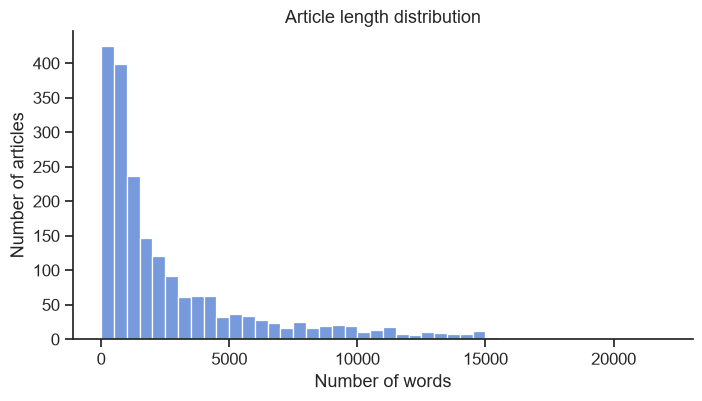

count     1986.000000
mean      2757.224068
std       3338.216121
min        200.000000
25%        566.000000
50%       1314.000000
75%       3587.000000
max      21805.000000
Name: n_words, dtype: float64

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(0, df["n_words"].max() + 500, 500)

sns.histplot(df["n_words"], bins=bins, ax=ax)
ax.set_xlabel("Number of words")
ax.set_ylabel("Number of articles")
ax.set_title("Article length distribution")
sns.despine()
plt.show()

df["n_words"].describe()

The database contains **1986 articles**. Their length is strongly right-skewed: half of the articles have fewer than **1,314 words** (median), and 75% fewer than about 3,600, while a small number of very long articles reach over **21,000 words**. As a result, the mean (2,757 words) is about twice the median. 

**Note**: No article is shorter than 200 words, which is the minimum length enforced by the crawler.

These large differences in length motivate the choices in the next section (Section 5): we use cosine similarity, which depends on the proportions of words rather than on the length of the text, and TF scaling, which prevents very long articles from dominating.

### Most frequent words

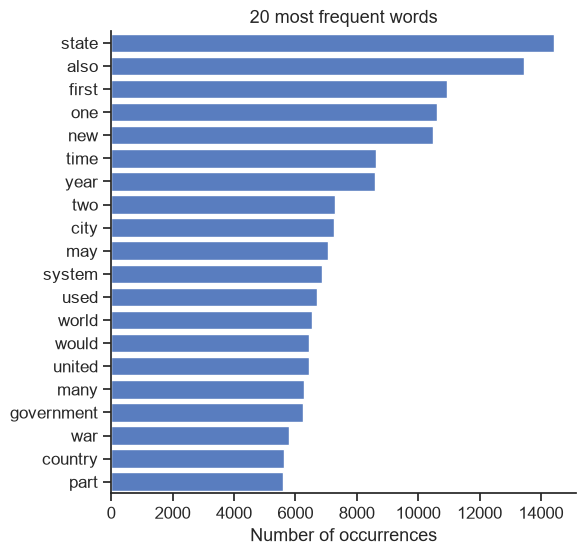

In [21]:
counts = Counter(t for tokens in df["tokens_lemma"] for t in tokens)
top = pd.DataFrame(counts.most_common(20), columns=["word", "count"])

fig, ax = plt.subplots(figsize=(6, 6))
sns.barplot(data=top, x="count", y="word", ax=ax)
ax.set_xlabel("Number of occurrences")
ax.set_ylabel("")
ax.set_title("20 most frequent words")
sns.despine()
plt.show()

The most frequent words are mostly general terms which are used in articles on almost any topic and say little about their content. Words like *city*, *government*, *war*, *country* and *united* also suggest that a large part of our database is about geography, history and politics.

In [22]:
for word, count in counts.most_common(3):
    share = df["tokens_lemma"].apply(lambda tokens: word in set(tokens)).mean()
    print(f"{word}: {count} occurrences, appears in {share:.1%} of articles")

state: 14428 occurrences, appears in 62.6% of articles
also: 13437 occurrences, appears in 85.5% of articles
first: 10945 occurrences, appears in 75.7% of articles


Looking at the top 3 words in more detail shows that the number of occurrences and the number of articles a word appears in are two different things. Although *state* is the most frequent word overall, it appears in only 62.6% of articles – it is used very often in some of them (e.g. articles about countries and politics), but not at all in others. *Also*, on the other hand, appears in 85.5% of articles, so it is spread almost evenly across the database.

## 5. Similarities

The goal of this step is to recommend articles from the database that are most similar to the ones the user has already visited. We implemented the recommender as a class, `Recommender`.

### How we score articles

1. **TF-IDF vectors.** Each article is turned into a vector of word weights. A word gets a high weight if it appears often in the article but rarely in the rest of the database. We use the following settings:
   - `min_df=2` – a word must appear in at least 2 articles,
   - `max_df=0.8` – words that appear in more than 80% of articles are ignored, as they say nothing about the topic (e.g. *also*, which appears in 85.5% of articles, see Section 4),
   - `ngram_range=(1,2)` – we also use pairs of words, such as *machine learning*,
   - `sublinear_tf=True` – repeated words count less, so long articles do not dominate.
2. **User profile.** The vectors of the visited articles are averaged into one profile. Articles that are not in the database are first downloaded and preprocessed in the same way as the database.
3. **Score.** Every article in the database gets a score equal to its **cosine similarity** to the profile, from 0 (nothing in common) to 1 (the same word proportions).
4. **Ranking.** Visited articles are excluded, and the articles with the highest scores are returned.


### Implementation

- `__init__` – stores the articles, the token column, the preprocessing function and a scraper, and sets up the TF-IDF vectorizer.
- `fit()` – builds the TF-IDF matrix and lookup tables from titles and URLs to rows of the matrix.
- `_new_vector(item)` – downloads and preprocesses an article that is not in the database and returns its TF-IDF vector.
- `recommend(items, top_n)` – scores all articles for the given titles or links and returns the top `top_n` recommendations.

In [23]:
class Recommender():
    
    def __init__(self, df, text_column, preprocess, scraper=None):
        self.df = df
        self.text_column = text_column
        self.preprocess = preprocess
        if scraper is None:
            scraper = WikiScraper([])
        self.scraper = scraper
        self.vectorizer = TfidfVectorizer(min_df=2, max_df=0.8, ngram_range=(1,2), sublinear_tf=True)
        self.tfidf_matrix = None
        
    def fit(self):
        texts = self.df[self.text_column].apply(" ".join)
        self.tfidf_matrix = self.vectorizer.fit_transform(texts)
        self.title_to_idx = {title: i for i, title in enumerate(self.df["title"])}
        self.url_to_idx = {url: i for i, url in enumerate(self.df["url"])}
        
    def _new_vector(self, item):
        if item.startswith("http"):
            url = item
        else:
            url = "https://en.wikipedia.org/wiki/" + item.replace(" ", "_")

        result = self.scraper._fetch_article(url)
        if result is None:
            print(f"Not found: {item}")
            return None

        article, links = result
        tokens = self.preprocess(article["content"])
        return self.vectorizer.transform([" ".join(tokens)]).toarray()
        
    def recommend(self, items, top_n=10):
        indices = []
        new_vectors = []
        for item in items:
            if item in self.title_to_idx:
                indices.append(self.title_to_idx[item])
            elif item in self.url_to_idx:
                indices.append(self.url_to_idx[item])
            else:
                vector = self._new_vector(item)
                if vector is not None:
                    new_vectors.append(vector)
        if not indices and not new_vectors:
            return pd.DataFrame(columns=["title", "url", "score"])

        vectors = [self.tfidf_matrix[indices].toarray()] + new_vectors
        all_vectors = np.vstack(vectors)
        profile = all_vectors.mean(axis=0)
        scores = cosine_similarity([profile], self.tfidf_matrix)[0]
        scores[indices] = -1

        top_indices = np.argsort(scores)[::-1][:top_n]
        result = self.df.iloc[top_indices][["title", "url"]].copy()
        result["score"] = scores[top_indices]
        return result.reset_index(drop=True)
    

We create the recommender on the stemmed tokens and fit it on the whole database. The same function, `custom_stemmer`, is passed as `preprocess`, so that articles downloaded on the fly are processed exactly like the database.

In [24]:
rec = Recommender(df, "tokens_stem", preprocess=custom_stemmer)
rec.fit()


In [25]:
for word in ["also", "first", "state"]: 
    print(word, word in rec.vectorizer.vocabulary_)

also False
first True
state True


We can check that the `max_df=0.8` filter works as described: *also*, which appears in 85.5% of articles (Section 4), is not part of the TF-IDF vocabulary, so it has no influence on the recommendations. 

### Similarity between pairs of articles

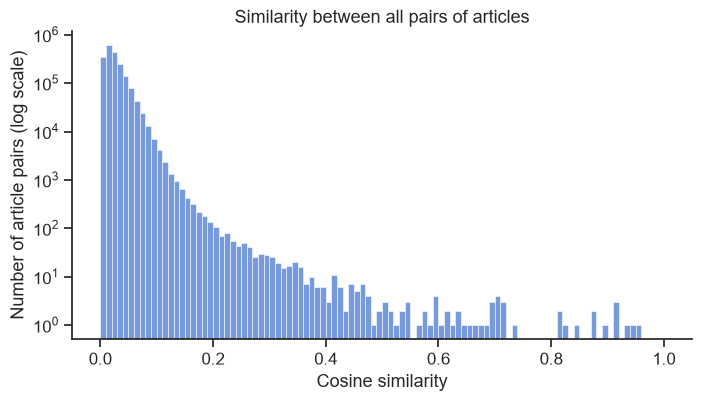

Number of pairs: 1971105
Mean similarity: 0.025
Pairs with similarity > 0.2: 0.04%


In [26]:
sim = cosine_similarity(rec.tfidf_matrix)
pairs = sim[np.triu_indices_from(sim, k=1)]

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(pairs, bins=np.arange(0, 1.01, 0.01), ax=ax)
ax.set_yscale("log")
ax.set_xlabel("Cosine similarity")
ax.set_ylabel("Number of article pairs (log scale)")
ax.set_title("Similarity between all pairs of articles")
ax.minorticks_off()
sns.despine()
plt.show()

print(f"Number of pairs: {len(pairs)}")
print(f"Mean similarity: {pairs.mean():.3f}")
print(f"Pairs with similarity > 0.2: {(pairs > 0.2).mean():.2%}")

The distribution of similarities between all pairs of articles is strongly right-skewed. Most pairs have almost nothing in common: the mean similarity is only **0.025**, and only **0.04%** of pairs (about 800) exceed 0.2. Note that the y-axis is logarithmic – on a linear scale, everything above about 0.2 would be invisible.

At the same time, the distribution has a long tail of outliers.

In [27]:
i_idx, j_idx = np.triu_indices_from(sim, k=1)
order = np.argsort(pairs)[::-1][:10]

top_pairs = pd.DataFrame({
    "article 1": df["title"].values[i_idx[order]],
    "article 2": df["title"].values[j_idx[order]],
    "similarity": pairs[order],
})
top_pairs

,article 1,article 2,similarity
0,França Júnior,Aluísio Azevedo,0.959114
1,"List of United States Supreme Court cases, vol...","List of United States Supreme Court cases, vol...",0.948076
2,França Júnior,José Mindlin,0.935372
3,Aluísio Azevedo,José Mindlin,0.918608
4,"List of United States Supreme Court cases, vol...","List of United States Supreme Court cases, vol...",0.918094
5,França Júnior,Roberto Campos,0.910688
6,Roberto Campos,Aluísio Azevedo,0.893573
7,Roberto Campos,José Mindlin,0.879518
8,"List of United States Supreme Court cases, vol...","List of United States Supreme Court cases, vol...",0.872428
9,Francisco de Aquino Correia,França Júnior,0.840824


In [28]:
a, b = top_pairs.loc[0, ["article 1", "article 2"]]
text_a = df[df["title"] == a]["content"].iloc[0]
text_b = df[df["title"] == b]["content"].iloc[0]

match = SequenceMatcher(None, text_a, text_b, autojunk=False).find_longest_match(0, len(text_a), 0, len(text_b))
print(f"Longest common fragment: {match.size} characters")
print(text_a[match.a : match.a + 300])

Longest common fragment: 6453 characters
. 1 (Adelino Fontoura): Luís Murat ►
Afonso d'Escragnolle Taunay ►
Ivan Monteiro de Barros Lins ►
Bernardo Élis ►
Evandro Lins e Silva ►
Ana Maria Machado
2 (Álvares de Azevedo): Coelho Neto ►
João Neves da Fontoura ►
João Guimarães Rosa ►
Mário Palmério ►
Tarcísio Padilha ►
Eduardo Giannetti da Fon


The most similar pairs are not always articles on the same topic. For example, the articles about the Brazilian writers *França Júnior* and *Aluísio Azevedo* (similarity 0.96) both include the same long navigation list of all members of the Brazilian Academy of Letters, which our scraper collected together with the main text. The many rare names in this list get high TF-IDF weights and dominate the similarity. 

### How to use the recommender

Pass a list of visited articles to `recommend`. They can be given as **titles** (exactly as on Wikipedia) or **links**, and do not have to be in our database – missing articles are downloaded automatically. The result is a table of recommended articles with their scores, sorted from the most similar.

In [29]:
visited = ["Black hole", "Neutron star", "Supernova"]  # change to your own titles or links
rec.recommend(visited, top_n=10)

,title,url,score
0,Milky Way,https://en.wikipedia.org/wiki/Milky_Way,0.369760
1,Solar System,https://en.wikipedia.org/wiki/Solar_System,0.314903
2,Neutron,https://en.wikipedia.org/wiki/Neutron,0.302982
3,Radioactive decay,https://en.wikipedia.org/wiki/Radioactive_decay,0.264987
4,Gravitational time dilation,https://en.wikipedia.org/wiki/Gravitational_ti...,0.209226
5,Magnetic field,https://en.wikipedia.org/wiki/Magnetic_fields,0.204097
6,Local Bubble,https://en.wikipedia.org/wiki/Local_Bubble,0.192825
7,Moons of Mars,https://en.wikipedia.org/wiki/Moons_of_Mars,0.187264
8,Chemistry,https://en.wikipedia.org/wiki/Chemistry,0.185503
9,Electric current,https://en.wikipedia.org/wiki/Electric_current,0.181158


## 6. Examples

This section shows example recommendations for different user profiles. To explain why an article was recommended, we use two charts:

- **Article contributions** (`plot_article_contributions`) – a heatmap in which the rows are the visited articles, the columns are the recommended articles, and each cell shows the cosine similarity between them. A dark cell means that the visited article is very similar to the recommendation, so it is the main reason why this article was recommended. This is especially useful when the user has visited articles on different topics – it shows which of the topics each recommendation comes from.

- **Word contributions** (`plot_word_contributions`) – a bar chart of the words that contributed most to the score of one chosen recommendation. For every word, its weight in the user profile is multiplied by its weight in the recommended article. A word contributes a lot only if it is important in both – a word that is frequent in the recommended article but absent from the visited ones contributes nothing. The contributions of all words add up exactly to the score, so the chart shows what the score is made of. Note that the words are shown after stemming (e.g. *paint* instead of *painting*).

The helper function `get_vector` returns the TF-IDF vector of an article – from the database if it is there, otherwise by downloading and preprocessing it.

In [30]:
def get_vector(rec, item):
    if item in rec.title_to_idx:
        return rec.tfidf_matrix[rec.title_to_idx[item]].toarray()
    if item in rec.url_to_idx:
        return rec.tfidf_matrix[rec.url_to_idx[item]].toarray()
    return rec._new_vector(item)


def plot_article_contributions(rec, visited, recommendations):
    vectors = np.vstack([get_vector(rec, item) for item in visited])
    rec_idx = [rec.title_to_idx[t] for t in recommendations["title"]]
    sim = cosine_similarity(vectors, rec.tfidf_matrix[rec_idx])
    labels = [v.split("/wiki/")[-1].replace("_", " ") for v in visited]

    fig, ax = plt.subplots(figsize=(10, 0.6 * len(visited) + 2))
    sns.heatmap(sim, xticklabels=recommendations["title"], yticklabels=labels,
                annot=True, fmt=".2f", cmap="Blues", ax=ax)
    ax.set_title("Similarity of each visited article to each recommendation")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.show()


def plot_word_contributions(rec, visited, title, top_k=15):
    profile = np.vstack([get_vector(rec, item) for item in visited]).mean(axis=0)
    article = rec.tfidf_matrix[rec.title_to_idx[title]].toarray()[0]
    contrib = profile * article / np.linalg.norm(profile)

    words = rec.vectorizer.get_feature_names_out()
    top = np.argsort(contrib)[::-1][:top_k]

    fig, ax = plt.subplots(figsize=(7, 5))
    sns.barplot(x=contrib[top], y=words[top], ax=ax)
    ax.set_xlabel("Contribution to score")
    ax.set_title(f"Why '{title}'? (score = {contrib.sum():.3f})")
    sns.despine()
    plt.show()

### Example 1

Our first user has two articles in their history, and both are about art.

In [31]:
visited = ["https://en.wikipedia.org/wiki/Pablo_Picasso",
           "https://en.wikipedia.org/wiki/Jackson_Pollock"]

recs = rec.recommend(visited, top_n=10)
display(recs)


,title,url,score
0,Jean-Auguste-Dominique Ingres,https://en.wikipedia.org/wiki/Jean_Auguste_Dom...,0.232207
1,Allen Jones (artist),https://en.wikipedia.org/wiki/Allen_Jones_(scu...,0.181464
2,John Lennon,https://en.wikipedia.org/wiki/John_Lennon,0.171712
3,Bohemian style,https://en.wikipedia.org/wiki/Bohemian_style,0.165678
4,Marlborough Fine Art,https://en.wikipedia.org/wiki/Marlborough_Fine...,0.158452
5,Michelangelo,https://en.wikipedia.org/wiki/Michelangelo,0.156860
6,Woody Allen,https://en.wikipedia.org/wiki/Woody_Allen,0.154946
7,The Beatles,https://en.wikipedia.org/wiki/The_Beatles,0.149261
8,Stephen King,https://en.wikipedia.org/wiki/Stephen_King,0.149162
9,Jaws (film),https://en.wikipedia.org/wiki/Jaws_(film),0.147364


Both articles are given as links and are not in our database, so they are downloaded on the fly. The top recommendations are mostly about art: the painters Ingres and Michelangelo, the artist Allen Jones and the gallery Marlborough Fine Art.

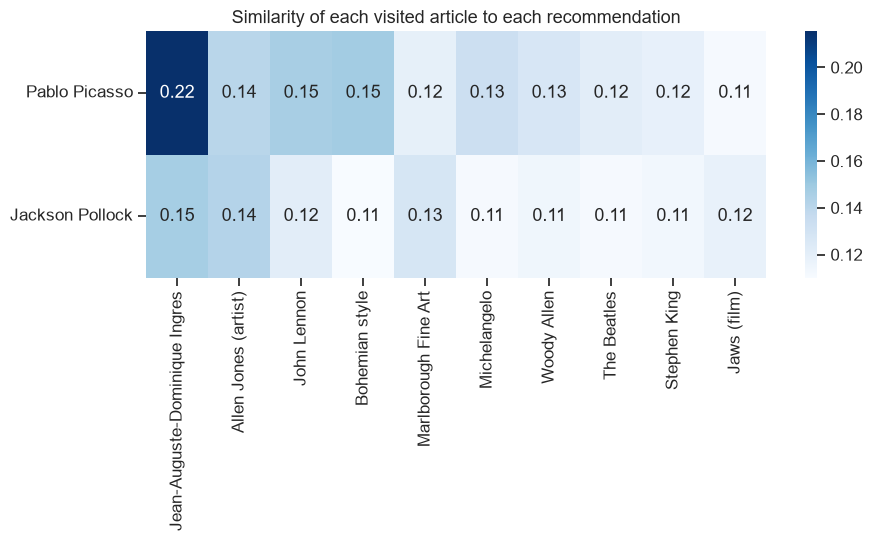

In [32]:
plot_article_contributions(rec, visited, recs)

The heatmap shows that *Picasso* is the main source of most recommendations – his row is darker for almost every article, while *Pollock* contributes mainly to *Ingres*, *Allen Jones* and *Marlborough Fine Art*.

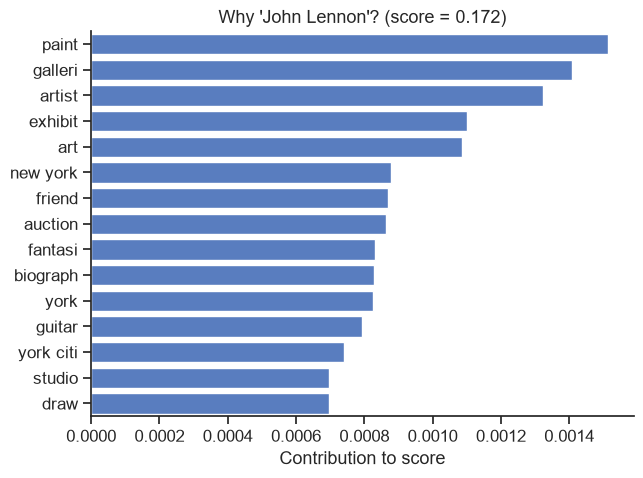

In [33]:
plot_word_contributions(rec, visited, "John Lennon")

At first, *John Lennon* looks like an unexpected recommendation. The word contribution chart explains it: the main contributing words are *paint*, *galleri*, *artist*, *exhibit* and *art* – Lennon studied at an art college and exhibited his drawings, so his article shares a lot of vocabulary with the articles about painters.

### Example 2

**Netherlands (*Clog*, *canals*, *Rijksmuseum*, *Delft*).** Our second user has four articles in their history that, at first glance, are about different things – a type of shoe, waterways, a museum and a city – but they share one hidden theme: the Netherlands. The input mixes a link and titles written in lowercase, which also works, because the missing articles are downloaded from Wikipedia.

In [34]:
visited = ["https://en.wikipedia.org/wiki/Clog",
           "canals", "rijksmuseum", "Delft"]  
recs = rec.recommend(visited, top_n=10)
display(recs)

,title,url,score
0,The Hague,https://en.wikipedia.org/wiki/The_Hague,0.198208
1,Netherlands,https://en.wikipedia.org/wiki/Netherlands,0.195856
2,Moscow,https://en.wikipedia.org/wiki/Moscow,0.156974
3,New York City,https://en.wikipedia.org/wiki/New_York_City,0.153076
4,Newcastle upon Tyne,https://en.wikipedia.org/wiki/Newcastle_upon_Tyne,0.151482
5,Ottawa,https://en.wikipedia.org/wiki/Ottawa,0.151226
6,"Tulsa, Oklahoma",https://en.wikipedia.org/wiki/Tulsa,0.147233
7,Rail transport,https://en.wikipedia.org/wiki/Railroad,0.144320
8,Panama,https://en.wikipedia.org/wiki/Panama,0.143536
9,Tampere,https://en.wikipedia.org/wiki/Tampere,0.142903


The top two recommendations, *The Hague* and *Netherlands*, show that the recommender picked up the common theme.

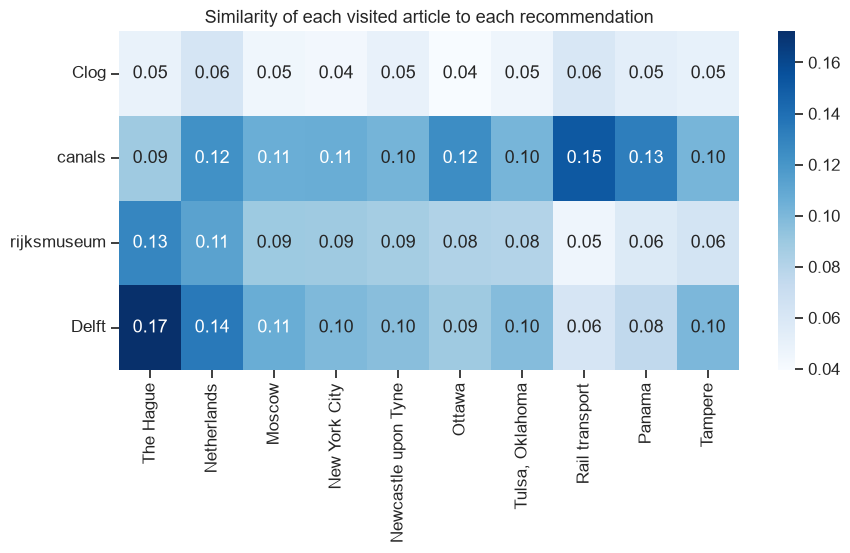

In [35]:
plot_article_contributions(rec, visited, recs)

*The Hague* and *Netherlands* come mainly from *Delft* and *Rijksmuseum*, while the other cities and *Rail transport* are driven by *canals*, and *Clog* contributes very little to any recommendation.

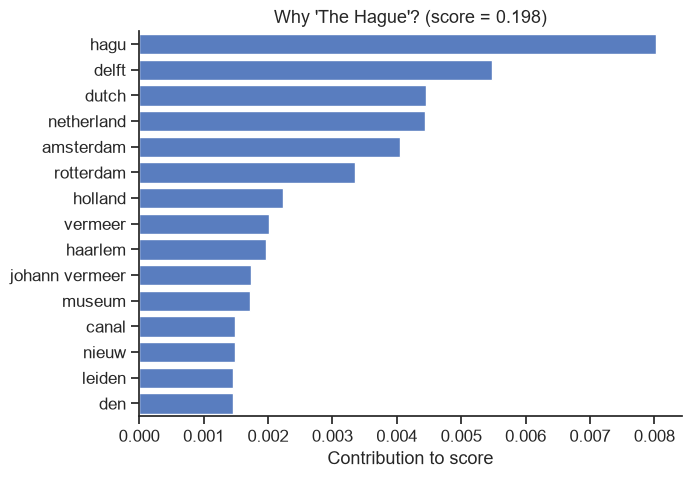

In [36]:
plot_word_contributions(rec, visited, "The Hague")

The score of *The Hague* comes from clearly Dutch words such as *hagu*, *delft*, *dutch*, *netherland* and *vermeer*, so the recommender correctly picked up the common theme.

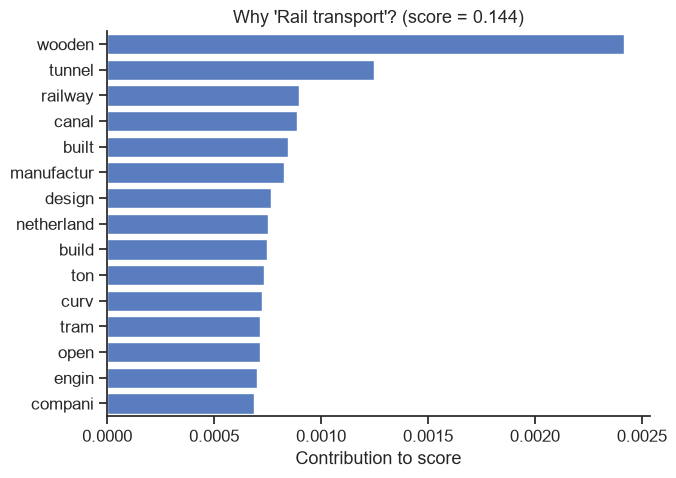

In [37]:
plot_word_contributions(rec, visited, "Rail transport")

*Rail transport* is recommended mainly because of the word *wooden* (wooden shoes vs. early wooden rails), which shows that TF-IDF matches words, not their meaning.

### Example 3

Our third user has a much more diverse history: five articles on unrelated topics – climate (*Climate change*), technology (*Electric vehicle*, *Python (programming language)*), food (*Sushi*) and sport (*Football*). Averaging such different articles produces a profile that is not focused on a single topic, so we want to see which of the interests dominate the recommendations.

In [38]:
visited = ["Climate change", "Electric vehicle", "Python (programming language)", "Sushi", "Football"]

recs = rec.recommend(visited, top_n=10)
display(recs)

,title,url,score
0,Rail transport,https://en.wikipedia.org/wiki/Railroad,0.200462
1,Engine,https://en.wikipedia.org/wiki/Engine,0.196308
2,Polychlorinated biphenyl,https://en.wikipedia.org/wiki/Polychlorinated_...,0.179455
3,Environmental policy,https://en.wikipedia.org/wiki/Environmental_po...,0.178539
4,Fire,https://en.wikipedia.org/wiki/Fire,0.173649
5,Kenya,https://en.wikipedia.org/wiki/Kenya,0.172828
6,Cloud,https://en.wikipedia.org/wiki/Cloudy,0.172235
7,Fuel oil,https://en.wikipedia.org/wiki/Fuel_oil,0.170826
8,Netherlands,https://en.wikipedia.org/wiki/Netherlands,0.170704
9,Malaria,https://en.wikipedia.org/wiki/Malaria,0.170464


Almost all recommendations are about energy, transport and the environment (*Rail transport*, *Engine*, *Environmental policy*, *Fuel oil*), while there is nothing about programming, food or football.

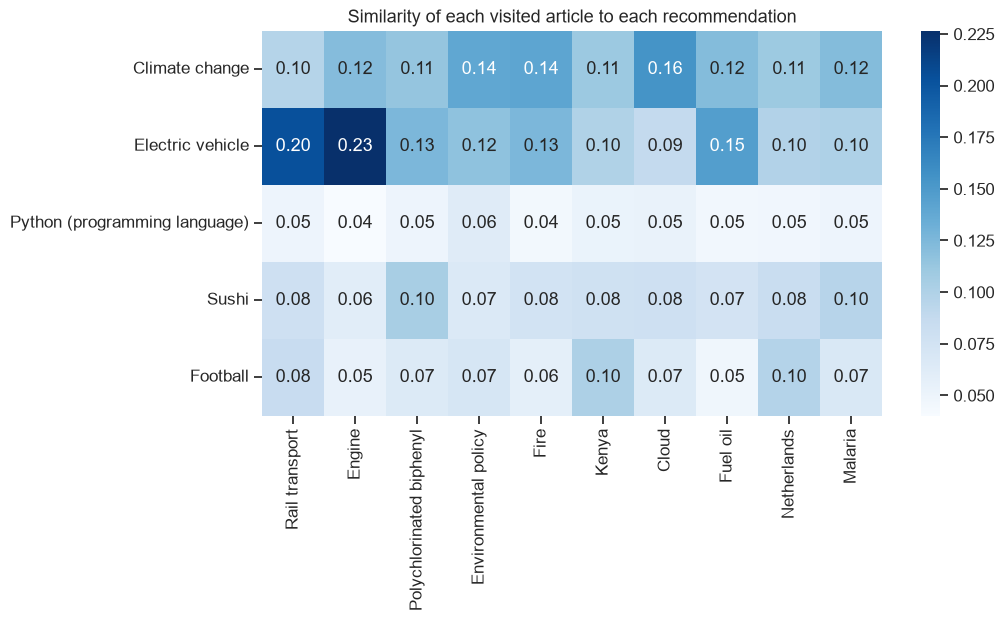

In [39]:
plot_article_contributions(rec, visited, recs)

The heatmap shows that the recommendations come almost entirely from *Climate change* and *Electric vehicle* – these two articles share a lot of vocabulary (energy, fuel, emissions), so they reinforce each other in the averaged profile and outweigh the other three interests, while *Python* has almost no influence on any recommendation.

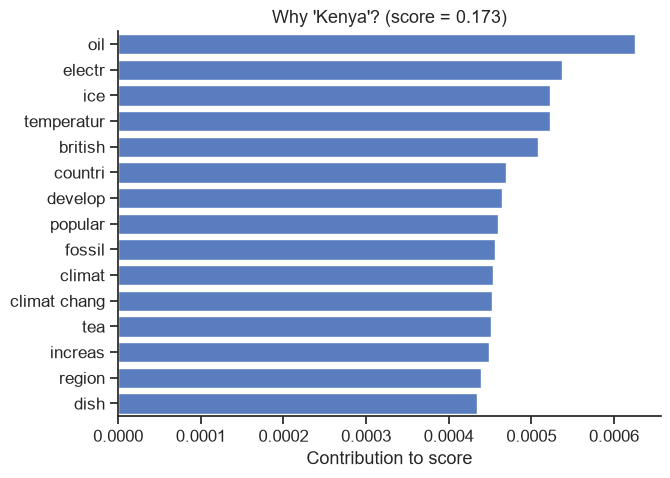

In [40]:
plot_word_contributions(rec, visited, "Kenya")

*Kenya* is not recommended because of one specific topic – its score is made of many small contributions from different interests, such as climate and energy (*oil*, *fossil*, *climat chang*), food (*tea*, *dish*) and general words (*british*, *countri*), which is typical for a long article about a country when the user profile is very diverse.

## 7. Conclusions

We built a recommender system for Wikipedia articles that crawls ~2000 articles, preprocesses them with stemming, represents them as TF-IDF vectors and recommends articles by their cosine similarity to the average profile of the user's visited articles. The input can be given as titles or links, also for articles that are not in our database.

### What works well

- For users with a **consistent interest**, the recommendations are accurate – e.g. articles about painters lead to other painters and galleries.
- The recommender can find a **hidden common theme**: a shoe, canals, a museum and a city led to *The Hague* and *Netherlands*.
- The explanation charts make every recommendation **interpretable** – we can see which visited article and which words are responsible for the score, even for surprising results such as *John Lennon* for an art profile.

### Limitations

- **TF-IDF matches words, not meaning.** The same word in a different context can connect unrelated articles, e.g. *wooden* (clogs vs. early railways) led to *Rail transport*.
- **Averaging favours some interests.** In a diverse profile, related interests (*Climate change* and *Electric vehicle*) reinforce each other and outweigh the rest, while unrelated ones (*Python*) have almost no influence. Very diverse profiles also tend to get general articles, such as countries, which match a little of everything.
- **The recommender can only suggest what is in the database.** Our randomised crawl covers some topics better than others, so for some interests there are simply no good matches.